In [6]:
import pandas as pd
import numpy as np
from wyklad12 import LinearRegression as lr
import matplotlib.pyplot as plt
from pandas.plotting import scatter_matrix


In [7]:
df_iris = pd.read_csv("http://www.math.uni.wroc.pl/~jagiella/files/p1python_r/iris_with_missing_data")
df_iris

,sepal length,sepal width,petal length,petal width,class
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,NaN,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0
...,...,...,...,...,...
145,6.7,3.0,5.2,2.3,2
146,6.3,2.5,5.0,1.9,2
147,6.5,3.0,5.2,2.0,2
148,6.2,3.4,5.4,2.3,2


In [8]:
df_zeros = df_iris.fillna(0)
df_zeros

,sepal length,sepal width,petal length,petal width,class
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,0.0,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0
...,...,...,...,...,...
145,6.7,3.0,5.2,2.3,2
146,6.3,2.5,5.0,1.9,2
147,6.5,3.0,5.2,2.0,2
148,6.2,3.4,5.4,2.3,2


In [9]:
df_mean = df_iris.fillna(df_iris.mean())
df_mean

,sepal length,sepal width,petal length,petal width,class
0,5.1,3.500000,1.400000,0.2,0
1,4.9,3.000000,1.400000,0.2,0
2,4.7,3.200000,3.854015,0.2,0
3,4.6,3.100000,1.500000,0.2,0
4,5.0,3.600000,1.400000,0.2,0
...,...,...,...,...,...
145,6.7,3.000000,5.200000,2.3,2
146,6.3,2.500000,5.000000,1.9,2
147,6.5,3.000000,5.200000,2.0,2
148,6.2,3.400000,5.400000,2.3,2


In [10]:
df_fill = df_iris.ffill().bfill()
df_fill

,sepal length,sepal width,petal length,petal width,class
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.4,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0
...,...,...,...,...,...
145,6.7,3.0,5.2,2.3,2
146,6.3,2.5,5.0,1.9,2
147,6.5,3.0,5.2,2.0,2
148,6.2,3.4,5.4,2.3,2


In [11]:
df_ins = pd.read_csv("http://www.math.uni.wroc.pl/~jagiella/files/p1python_r/insurance_charges_dataset.csv")
df_ins["smoker"] = np.where(df_ins["smoker"] == "yes", 1, 0)
df_ins = pd.get_dummies(df_ins, columns=['region'], dtype=int)
df_ins["female"] = np.where(df_ins["sex"] == "female", 1, 0)
df_ins["male"] = np.where(df_ins["sex"] == "male", 1, 0)
df_ins = df_ins.drop(columns=["sex"])
lst = df_ins.columns.to_list()
lst.insert(1, lst.pop())
lst.insert(1, lst.pop())
df_ins = df_ins[lst]
df_ins

,age,female,male,bmi,children,smoker,charges,region_northeast,region_northwest,region_southeast,region_southwest
0,19,1,0,27.900,0,1,16884.92400,0,0,0,1
1,18,0,1,33.770,1,0,1725.55230,0,0,1,0
2,28,0,1,33.000,3,0,4449.46200,0,0,1,0
3,33,0,1,22.705,0,0,21984.47061,0,1,0,0
4,32,0,1,28.880,0,0,3866.85520,0,1,0,0
...,...,...,...,...,...,...,...,...,...,...,...
1333,50,0,1,30.970,3,0,10600.54830,0,1,0,0
1334,18,1,0,31.920,0,0,2205.98080,1,0,0,0
1335,18,1,0,36.850,0,0,1629.83350,0,0,1,0
1336,21,1,0,25.800,0,0,2007.94500,0,0,0,1


In [28]:
model = lr()
y = df_ins.iloc[:, 6].to_numpy()
x = df_ins.drop(["charges"], axis=1).to_numpy()
#X = x.reshape(-1, 1)
model.fit(x, y)
model.predict(x)
#plt.scatter(x, y)
#plt.scatter(x, y_predicted)

LinAlgError: Singular matrix

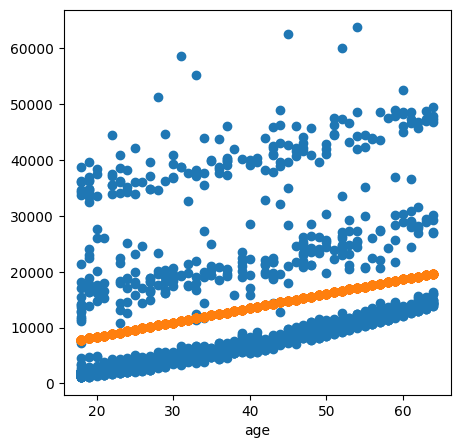

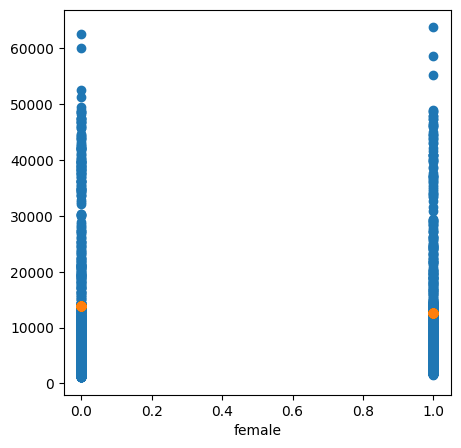

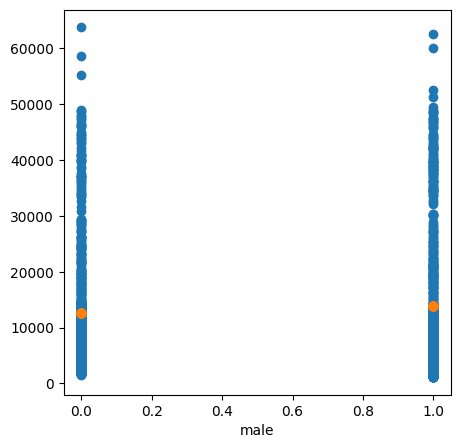

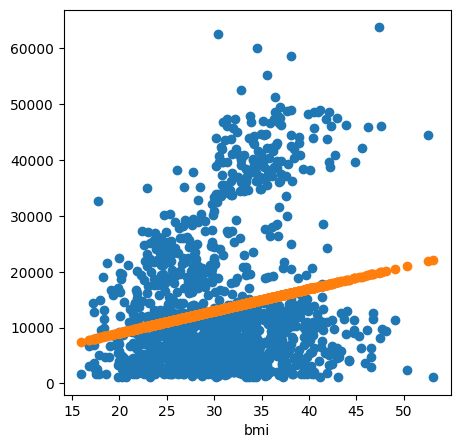

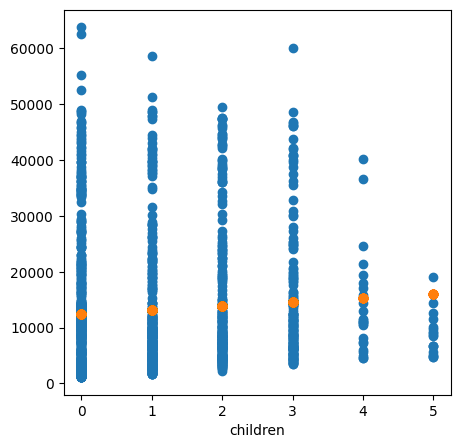

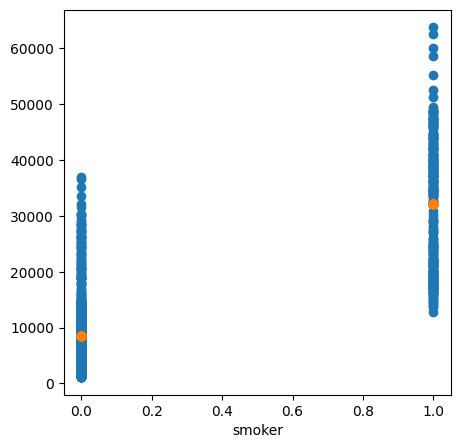

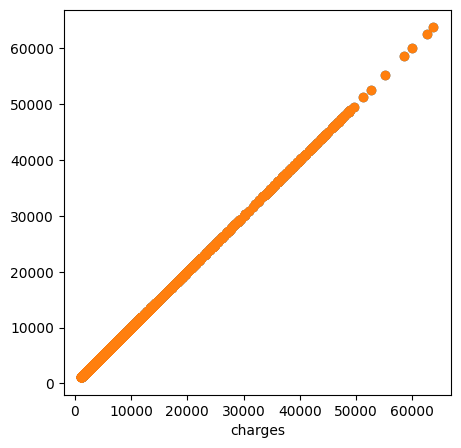

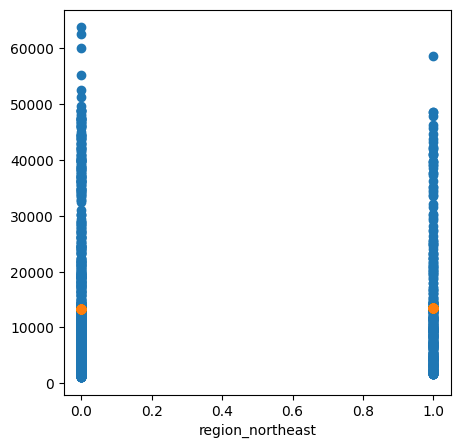

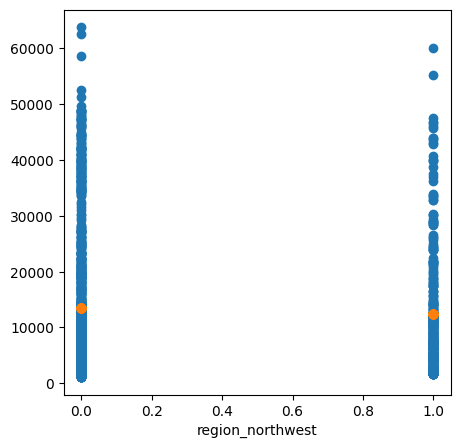

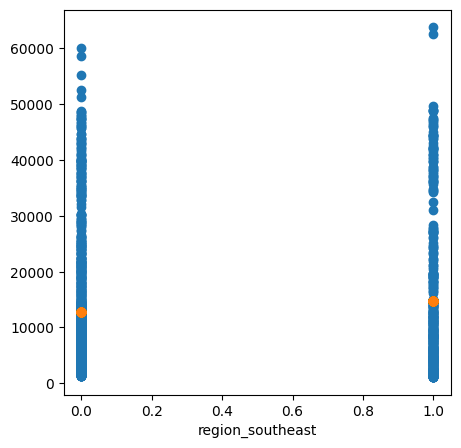

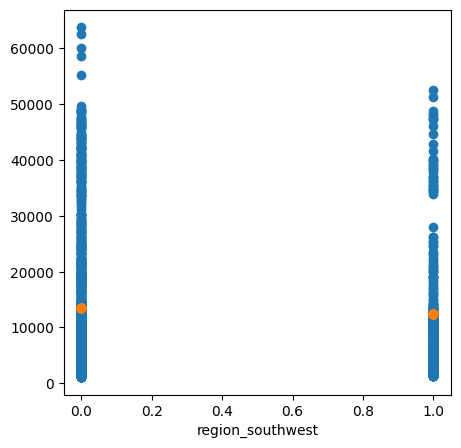

In [13]:
model = lr()
y = df_ins.iloc[:, 6].to_numpy()
for i in df_ins.columns:
    fig, ax = plt.subplots(figsize=(5, 5))
    x = df_ins[i].to_numpy()

    X = x.reshape(-1, 1)
    model.fit(X, y)
    y_predicted = model.predict(X)

    plt.scatter(x, y)
    plt.scatter(x, y_predicted)
    plt.xlabel(f"{i}")

In [16]:
np.random.seed(42)
N = 1000

area = np.random.randint(30, 300, N)
year = np.random.randint(1950, 2025, N)
location = np.random.choice(["centrum", "przedmieścia", "wieś"], N, p=[0.3, 0.5, 0.2])

loc_bonus = {"centrum": 1.5, "przedmieścia": 1.0, "wieś": 0.65}
loc_factor = np.array([loc_bonus[l] for l in location])

base_price = (area * 5000 * loc_factor + (year - 1950) * 700 + np.random.normal(0, 20000, N))
price = np.maximum(base_price, 50000)
price = (price // 1000) * 1000

df_houses = pd.DataFrame({"area": area, "year": year, "location": location, "price": price})
df_houses.to_csv("houses.csv", index=False)
df_houses

,area,year,location,price
0,132,1976,przedmieścia,630000.0
1,136,2006,wieś,493000.0
2,101,1980,przedmieścia,510000.0
3,218,1955,przedmieścia,1099000.0
4,50,1989,przedmieścia,276000.0
...,...,...,...,...
995,194,1997,przedmieścia,1010000.0
996,182,1978,wieś,613000.0
997,105,1959,przedmieścia,508000.0
998,116,2007,wieś,426000.0


In [17]:
df_houses = pd.get_dummies(df_houses, columns=['location'], dtype=int)
df_houses

,area,year,price,location_centrum,location_przedmieścia,location_wieś
0,132,1976,630000.0,0,1,0
1,136,2006,493000.0,0,0,1
2,101,1980,510000.0,0,1,0
3,218,1955,1099000.0,0,1,0
4,50,1989,276000.0,0,1,0
...,...,...,...,...,...,...
995,194,1997,1010000.0,0,1,0
996,182,1978,613000.0,0,0,1
997,105,1959,508000.0,0,1,0
998,116,2007,426000.0,0,0,1


In [30]:
model = lr()
y = df_houses.iloc[:, 2].to_numpy()
x = df_houses.drop(["price"], axis=1).to_numpy()
#X = x.reshape(-1, 1)
model.fit(x, y)
model.predict(x)
#plt.scatter(x, y)
#plt.scatter(x, y_predicted)

array([-15976273.24486434,  24143326.64608815, -11118560.45028418,
       -42677222.83990513,    103953.94586633, -33178801.37128361,
        19035876.79905304,  44529247.79315156, -38916781.5248162 ,
        10842394.18450353, -28570071.2309998 , -16874627.9864959 ,
        34324530.391701  ,  14643942.16092588,  34822488.69625174,
       -48455841.01541333,  18810414.8046359 ,  39938396.41716471,
        20977526.63093972,  17901123.37222609,  -4644498.88826461,
       -16265893.9211363 , -11983427.86184052, -22635367.39770713,
       -36223441.71866333,    572210.91921972, -38091797.73707688,
        -1756914.21925159,  27193393.26662648,    543263.98618144,
        21627868.73885764,  22413723.30093902, -17372586.29104663,
       -24042408.516286  ,  42275218.0273138 ,  25278757.33065461,
        -5915943.40821895,  -4134088.09257551, -22811056.23852988,
        32529545.32717969,  49887950.49300125, -14826665.65041821,
        38105252.14756818,  43870740.57419804,  44687057.86967

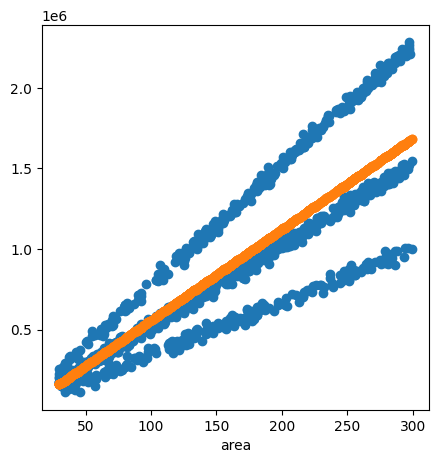

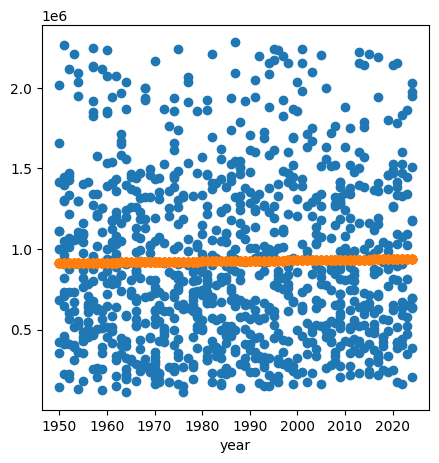

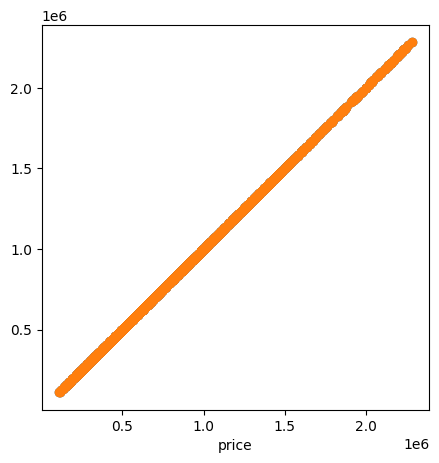

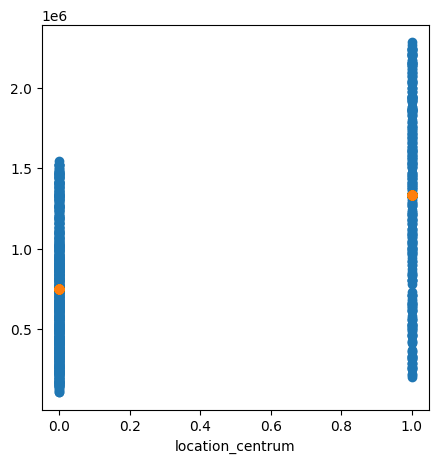

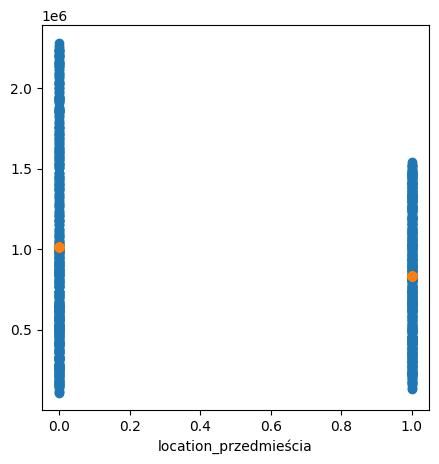

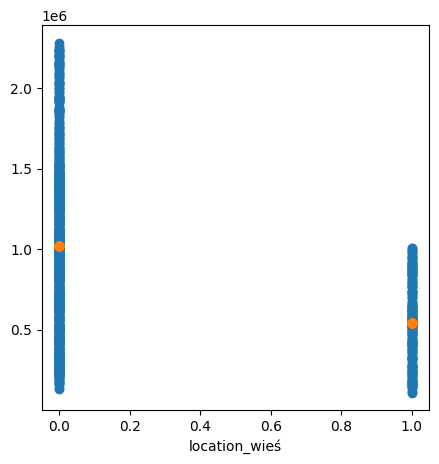

In [19]:
model = lr()
y = df_houses.iloc[:, 2].to_numpy()
for i in df_houses.columns:
    fig, ax = plt.subplots(figsize=(5, 5))
    x = df_houses[i].to_numpy()

    X = x.reshape(-1, 1)
    model.fit(X, y)
    y_predicted = model.predict(X)

    plt.scatter(x, y)
    plt.scatter(x, y_predicted)
    plt.xlabel(f"{i}")